In [1]:
import numpy as np
import scipy as sp
import xarray as xr
import seaborn as sea
import matplotlib.pyplot as plt

# Could be nice plotting the histograms of Norkyst and Havbris "on top" of eachother to compare more easily

In [2]:
#NK 
nk_path = '/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/saved_nc'
nk_year = xr.open_dataset(f'{nk_path}/yearly_average.nc')
nk_month = xr.open_dataset(f'{nk_path}/monthly_average.nc')
#HB
from dataloader_inf import open_dataset
hb_path = '/lustre/storeB/project/fou/hi/foccus/malene/run-ocean-anemoi/ppi/external_checkpoint_inference/results/rollout_benchmark_lr3.5e6-rs3-i0-m3/step_51000_e14/resampled_means'
hb_year = open_dataset(f'{hb_path}/yearly_mean.nc').ds
hb_month = open_dataset(f'{hb_path}/monthly_mean.nc').ds

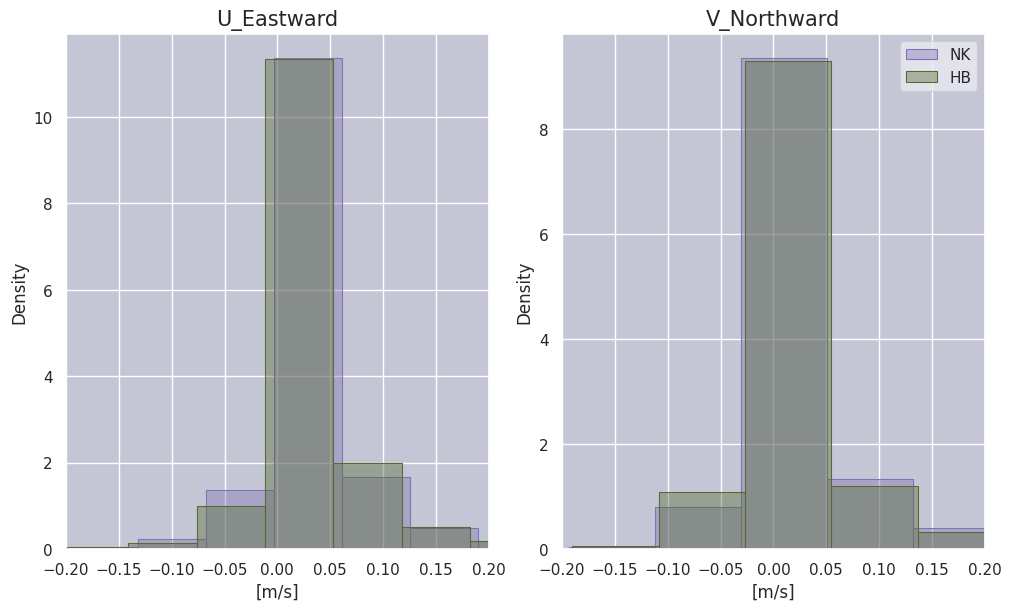

In [3]:
variables = ['u_eastward', 'v_northward']
sea.set_theme(style="darkgrid")
data_nk = {var: nk_year[var].isel({'time' : 0}).values.ravel() for var in variables}
data_nk = {var : values[~np.isnan(values)] for var, values in data_nk.items()}
data_hb = {var: hb_year[var].isel({'time' : 0}).values.ravel() for var in variables}
data_hb = {var : values[~np.isnan(values)] for var, values in data_hb.items()}
fig, ax = plt.subplots(1,2, figsize = (10, 6), layout = 'compressed')
titles = ['U_Eastward', 'V_Northward']
U = ax[0]
V = ax[1]

sea.histplot(data_nk['u_eastward'], bins = 30, ax = U, stat='density', color = 'm', edgecolor = 'm', label = 'NK', alpha = 0.4)
sea.histplot(data_hb['u_eastward'], bins = 30, ax = U, stat='density', color = 'darkolivegreen',  edgecolor = 'darkolivegreen', label = 'HB', alpha = 0.4)
U.set_title('U_Eastward', fontsize = 15)

sea.histplot(data_nk['v_northward'], bins = 30, ax = V, stat='density', color = 'm', edgecolor = 'm', label = 'NK', alpha = 0.4)
sea.histplot(data_hb['v_northward'], bins = 30, ax = V, stat='density', color = 'darkolivegreen', edgecolor = 'darkolivegreen', label = 'HB', alpha = 0.4)
V.set_title('V_Northward', fontsize = 15)

for i in range(0,2):
    ax[i].set_facecolor("#C4C6D5")
    ax[i].set_xlim(-0.2, 0.2)
    ax[i].set_xlabel('[m/s]')
plt.legend()

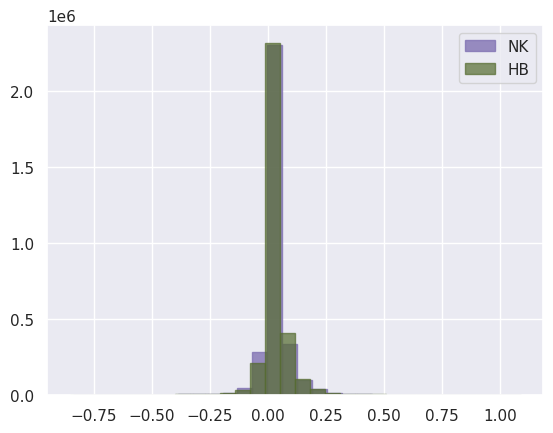

In [7]:
variables = ['u_eastward', 'v_northward']
sea.set_theme(style="darkgrid")
data_nk = {var: nk_year[var].isel({'time' : 0}).values.ravel() for var in variables}
data_nk = {var : values[~np.isnan(values)] for var, values in data_nk.items()}
data_hb = {var: hb_year[var].isel({'time' : 0}).values.ravel() for var in variables}
data_hb = {var : values[~np.isnan(values)] for var, values in data_hb.items()}

plt.hist(data_nk['u_eastward'], bins = 30, color = 'm', edgecolor = 'm', label = 'NK', alpha = 0.8)
plt.hist(data_hb['u_eastward'], bins = 30, color = 'darkolivegreen',  edgecolor = 'darkolivegreen', label = 'HB', alpha = 0.7)
U.set_title('U_Eastward', fontsize = 15)

plt.legend()

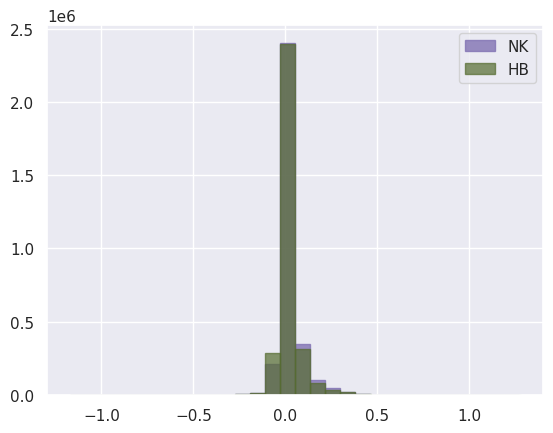

In [8]:
plt.hist(data_nk['v_northward'], bins = 30, color = 'm', edgecolor = 'm', label = 'NK', alpha = 0.8)
plt.hist(data_hb['v_northward'], bins = 30, color = 'darkolivegreen', edgecolor = 'darkolivegreen', label = 'HB', alpha = 0.7)
V.set_title('V_Northward', fontsize = 15)
plt.legend()